# AlphaGenome RNA variant predictions

Score REF/ALT variants from Notebook 1 and keep RNA predictions for Hi-C linked target genes. The predictions use centered 1 Mb windows.

## 1. Load variant inputs

In [ ]:
from pathlib import Path
import os
import time
import pandas as pd
from tqdm.auto import tqdm
from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers

# Read Notebook 1 outputs and save RNA scores
DATA_DIR = Path("../results")
OUT_DIR = DATA_DIR / "alphagenome_rna"
OUT_DIR.mkdir(parents=True, exist_ok=True)

VARIANT_FILE = DATA_DIR / "alphagenome_variant_input.clean.tsv"
PAIRS_FILE = DATA_DIR / "alphagenome_SNP_loop_gene_input.tsv"

for path in (VARIANT_FILE, PAIRS_FILE):
    if not path.is_file():
        raise FileNotFoundError(path)

variants = pd.read_csv(VARIANT_FILE, sep="\t", dtype={"rsid": str, "chr": str, "REF": str, "ALT": str})
pairs = pd.read_csv(PAIRS_FILE, sep="\t", dtype={"rsid": str, "target_gene": str})

# Keep unique substitutions and matching target genes
variants = variants.drop_duplicates(subset=["rsid", "chr", "position", "REF", "ALT"]).copy()
variants["position"] = pd.to_numeric(variants["position"], errors="raise").astype(int)
variants["variant_key"] = (variants["chr"] + ":" + variants["position"].astype(str)
                           + ":" + variants["REF"] + ">" + variants["ALT"])
variants = variants.reset_index(drop=True)
target_map = pairs[["rsid", "target_gene"]].dropna().drop_duplicates()

if variants["variant_key"].duplicated().any():
    raise ValueError("Duplicate genomic variants found; check REF/ALT annotations")

print(f"Variants: {len(variants):,}")
print(f"SNP–gene pairs: {len(target_map):,}")

Variants: 1,174
SNP–gene pairs: 1,358


## 2. Connect to AlphaGenome

In [ ]:
# Use ALPHAGENOME_API_KEY from your environment
KEY = os.environ.get("ALPHAGENOME_API_KEY", "")
if not KEY:
    raise ValueError("Set ALPHAGENOME_API_KEY before running the notebook")

# Connect to AlphaGenome
model = dna_client.create(api_key=KEY)
model.output_metadata(dna_client.Organism.HOMO_SAPIENS)
rna_scorer = variant_scorers.RECOMMENDED_VARIANT_SCORERS["RNA_SEQ"]
print("AlphaGenome connected")

AlphaGenome connected


## 3. Optional small test

Test first 10 variants before running full dataset

In [ ]:
# Build AlphaGenome variants and 1 Mb windows
TEST_N = 10
test = variants.head(TEST_N)
ag_variants = []
intervals = []
for row in test.itertuples(index=False):
    v = genome.Variant(chromosome=row.chr, position=int(row.position),
                       reference_bases=row.REF, alternate_bases=row.ALT)
    ag_variants.append(v)
    intervals.append(v.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB))

# Test RNA scores
start = time.time()
scores = model.score_variants(
    intervals=intervals, variants=ag_variants,
    variant_scorers=[rna_scorer],
    organism=dna_client.Organism.HOMO_SAPIENS,
    progress_bar=True, max_workers=5,
)
test_scores = variant_scorers.tidy_scores(scores, match_gene_strand=True)
test_scores["variant_key"] = test_scores["variant_id"].map(str)
print(f"Tested {len(test)} variants in {time.time() - start:.1f} seconds")
print(f"RNA score rows: {len(test_scores):,}")
display(test_scores.head())

  0%|          | 0/10 [00:00<?, ?it/s]

Tested 10 variants in 2.7 seconds
RNA score rows: 110,187


,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,raw_score,quantile_score,variant_key
0,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000040487,SLC66A1,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,0.001921,0.834498,chr1:19375162:T>A
1,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000053371,AKR7A2,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,-0.000955,-0.661907,chr1:19375162:T>A
2,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000053372,MRTO4,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,-0.000803,-0.611615,chr1:19375162:T>A
3,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000077549,CAPZB,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,0.000189,0.356342,chr1:19375162:T>A
4,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000127463,EMC1,protein_coding,-,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,0.000866,0.642441,chr1:19375162:T>A


## 4. Score all variants

Run all variants in batches of 25. Save each batch so finished batches are skipped if the notebook is rerun.

In [4]:
# Full-run settings
BATCH_SIZE = 25
MAX_WORKERS = 5
BATCH_DIR = OUT_DIR / "rna_batches"
BATCH_DIR.mkdir(parents=True, exist_ok=True)
FAILED_FILE = OUT_DIR / "failed_batches.tsv"
SCORES_FILE = OUT_DIR / "alphagenome_RNA_target_gene_scores.tsv"

# Identify lung-related RNA tracks
def lung_tracks(df):
    mask = pd.Series(False, index=df.index)
    for col in ["ontology_curie", "biosample_name", "biosample_type", "gtex_tissue"]:
        if col in df.columns:
            mask |= df[col].fillna("").astype(str).str.contains(
                "lung|UBERON:0002048", case=False, regex=True
            )
    return mask


In [ ]:
# Process all variants in batches
batches = [variants.iloc[i:i + BATCH_SIZE] for i in range(0, len(variants), BATCH_SIZE)]
completed = sorted(BATCH_DIR.glob("batch_*.tsv"))
print(f"Variants: {len(variants):,} | Batches: {len(batches)} | Completed: {len(completed)}")

for batch_no, batch in tqdm(enumerate(batches, 1), total=len(batches), desc="RNA batches"):
    batch_file = BATCH_DIR / f"batch_{batch_no:03d}.tsv"
    empty_marker = BATCH_DIR / f"batch_{batch_no:03d}.empty"
    if batch_file.exists() or empty_marker.exists():
        continue

    # Build variants and centered 1 Mb intervals
    ag_variants, intervals = [], []
    for row in batch.itertuples(index=False):
        v = genome.Variant(
            chromosome=row.chr, position=int(row.position),
            reference_bases=row.REF, alternate_bases=row.ALT
        )
        ag_variants.append(v)
        intervals.append(v.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB))

    try:
        # Score RNA effects
        scores = model.score_variants(
            intervals=intervals, variants=ag_variants,
            variant_scorers=[rna_scorer],
            organism=dna_client.Organism.HOMO_SAPIENS,
            progress_bar=False, max_workers=MAX_WORKERS,
        )
        tidy = variant_scorers.tidy_scores(scores, match_gene_strand=True)
        tidy["variant_key"] = tidy["variant_id"].map(str)

        # Retain scores for candidate target genes
        lookup = batch[["variant_key", "rsid", "chr", "position", "REF", "ALT"]]
        tidy = tidy.merge(lookup, on="variant_key", how="left", validate="many_to_one")
        if tidy["rsid"].isna().any():
            raise ValueError("Some RNA scores did not match input variants")
        target_scores = tidy.merge(
            target_map, left_on=["rsid", "gene_name"],
            right_on=["rsid", "target_gene"], how="inner"
        )
        target_scores["is_lung_track"] = lung_tracks(target_scores)

        # Save each completed batch (including batches with no target-gene scores)
        if target_scores.empty:
            empty_marker.touch()
        else:
            temp_file = batch_file.with_suffix(".tmp")
            target_scores.to_csv(temp_file, sep="\t", index=False)
            temp_file.replace(batch_file)
    except Exception as exc:
        with FAILED_FILE.open("a") as handle:
            handle.write(f"{batch_no}\t{str(exc).replace(chr(10), ' ')}\n")
        print(f"Batch {batch_no} failed: {exc}")

print("Finished processing available batches")

Variants: 1,174 | Batches: 47 | Completed: 0


RNA batches:   0%|          | 0/47 [00:00<?, ?it/s]

Finished processing available batches


## 5. Combine saved scores

Combine the saved batch files into one table without making new AlphaGenome calls.

In [ ]:
# Combine saved batch scores
batch_files = sorted(BATCH_DIR.glob("batch_*.tsv"))
completed_count = len(batch_files) + len(list(BATCH_DIR.glob("batch_*.empty")))
print(f"Completed batches: {completed_count}/{len(batches)}")

if batch_files:
    # Write one header and append remaining batches
    with SCORES_FILE.open("w") as destination:
        for i, file in enumerate(batch_files):
            with file.open() as source:
                if i > 0:
                    next(source, None)
                for line in source:
                    destination.write(line)

    result = pd.read_csv(SCORES_FILE, sep="\t", low_memory=False)
    print(f"Target-gene score rows: {len(result):,}")
    print(f"Scored variants with target-gene matches: {result['variant_key'].nunique():,}")
    print(f"Target genes: {result['gene_name'].nunique():,}")
    print(f"Lung-track rows: {result['is_lung_track'].sum():,}")
    display(result.head())
else:
    print("No target-gene score batches saved yet")

Completed batches: 47/47
Target-gene score rows: 740,887
Scored variants with target-gene matches: 1,103
Target genes: 179
Lung-track rows: 29,955


,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,raw_score,quantile_score,variant_key,rsid,chr,position,REF,ALT,target_gene,is_lung_track
0,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000077549,CAPZB,protein_coding,-,NaN,NaN,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,0.000189,0.356342,chr1:19375162:T>A,rs7519565,chr1,19375162,T,A,CAPZB,False
1,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000158747,NBL1,protein_coding,+,NaN,NaN,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,0.000647,0.578814,chr1:19375162:T>A,rs7519565,chr1,19375162,T,A,NBL1,False
2,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000173436,MICOS10,protein_coding,+,NaN,NaN,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,-0.000532,-0.519734,chr1:19375162:T>A,rs7519565,chr1,19375162,T,A,MICOS10,False
3,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000270136,MICOS10-NBL1,protein_coding,+,NaN,NaN,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,0.000535,0.531989,chr1:19375162:T>A,rs7519565,chr1,19375162,T,A,MICOS10-NBL1,False
4,chr1:19375162:T>A,chr1:18850874-19899450:.,ENSG00000077549,CAPZB,protein_coding,-,NaN,NaN,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,0.000688,0.652282,chr1:19375162:T>A,rs7519565,chr1,19375162,T,A,CAPZB,False


## 6. Summarize RNA prediction coverage

Count variants, target genes, and variant–gene pairs with RNA predictions.

In [ ]:
# Summarize RNA prediction coverage
scored_pairs = result[
    ["variant_key", "target_gene"]
].drop_duplicates()

print(f"Input variants: {len(variants):,}")
print(f"Variants with RNA scores: {result['variant_key'].nunique():,}")
print(f"Target genes with RNA scores: {result['target_gene'].nunique():,}")
print(f"Unique variant-gene pairs scored: {len(scored_pairs):,}")
print(f"Total RNA score rows: {len(result):,}")

Input variants: 1,174
Variants with RNA scores: 1,103
Target genes with RNA scores: 179
Unique variant-gene pairs scored: 1,976
Total RNA score rows: 740,887



## 7. Examine lung-related RNA predictions

Keep scores from lung-related biosamples and save them separately.

In [ ]:
# Keep lung-related RNA scores
lung_scores = result[result["is_lung_track"]].copy()

lung_pairs = lung_scores[
    ["variant_key", "target_gene"]
].drop_duplicates()

print(f"Lung RNA score rows: {len(lung_scores):,}")
print(f"Variants with lung RNA scores: {lung_scores['variant_key'].nunique():,}")
print(f"Target genes with lung RNA scores: {lung_scores['target_gene'].nunique():,}")
print(f"Unique variant-gene pairs with lung scores: {len(lung_pairs):,}")

# Check lung-related biosamples
lung_biosamples = lung_scores[
    ["biosample_name", "biosample_type", "gtex_tissue"]
].drop_duplicates()

display(lung_biosamples)

# Save lung-specific scores
LUNG_SCORES_FILE = OUT_DIR / "alphagenome_RNA_lung_target_gene_scores.tsv"
lung_scores.to_csv(LUNG_SCORES_FILE, sep="\t", index=False)

print(f"Saved: {LUNG_SCORES_FILE.name}")

Lung RNA score rows: 29,955
Variants with lung RNA scores: 1,103
Target genes with lung RNA scores: 179
Unique variant-gene pairs with lung scores: 1,976


,biosample_name,biosample_type,gtex_tissue
252,fibroblast of lung,primary_cell,NaN
324,epithelial cell of alveolus of lung,primary_cell,NaN
376,lung microvascular endothelial cell,primary_cell,NaN
420,bronchus fibroblast of lung,primary_cell,NaN
880,lung,tissue,NaN
952,left lung,tissue,NaN
956,upper lobe of right lung,tissue,NaN
960,lower lobe of right lung,tissue,NaN
1048,upper lobe of left lung,tissue,NaN
1052,lower lobe of left lung,tissue,NaN


Saved: alphagenome_RNA_lung_target_gene_scores.tsv



## 8. Final RNA results

Check for duplicate rows and make sure both output files were saved.

In [ ]:
# Check required columns and duplicate score records
required_columns = [
    "variant_key", "rsid", "target_gene",
    "raw_score", "quantile_score", "is_lung_track"
]

missing_columns = [
    col for col in required_columns if col not in result.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

duplicate_rows = result.duplicated().sum()

print(f"Total RNA score rows: {len(result):,}")
print(f"Exact duplicate rows: {duplicate_rows:,}")

# Confirm output files
for file in [SCORES_FILE, LUNG_SCORES_FILE]:
    print(f"{file.name}: {'Saved' if file.exists() else 'Missing'}")

Total RNA score rows: 740,887
Exact duplicate rows: 0
alphagenome_RNA_target_gene_scores.tsv: Saved
alphagenome_RNA_lung_target_gene_scores.tsv: Saved


## 9. Plot RNA predictions

Plot variant coverage, RNA effect scores, and the number of scores from each lung biosample.


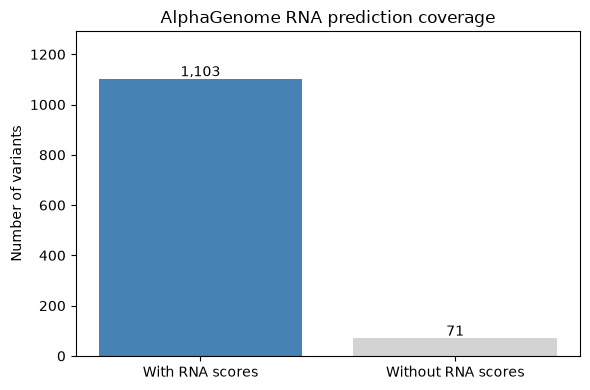

In [ ]:
import matplotlib.pyplot as plt

# Count variants with and without target-gene scores
n_input = len(variants)
n_scored = result["variant_key"].nunique()

labels = ["With RNA scores", "Without RNA scores"]
counts = [n_scored, n_input - n_scored]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, counts, color=["steelblue", "lightgray"])

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 10,
        f"{count:,}",
        ha="center"
    )

plt.ylabel("Number of variants")
plt.title("AlphaGenome RNA prediction coverage")
plt.ylim(0, n_input * 1.1)
plt.tight_layout()
plt.show()

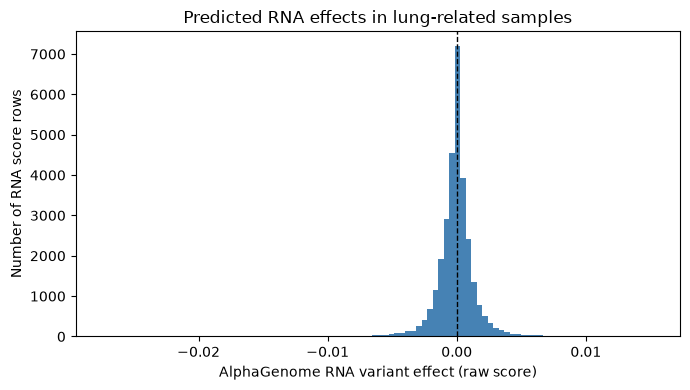

In [ ]:
# Plot predicted RNA effects in lung-related tracks
plt.figure(figsize=(7, 4))

plt.hist(
    lung_scores["raw_score"].dropna(),
    bins=100,
    color="steelblue",
    edgecolor="none"
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("AlphaGenome RNA variant effect (raw score)")
plt.ylabel("Number of RNA score rows")
plt.title("Predicted RNA effects in lung-related samples")

plt.tight_layout()
plt.show()

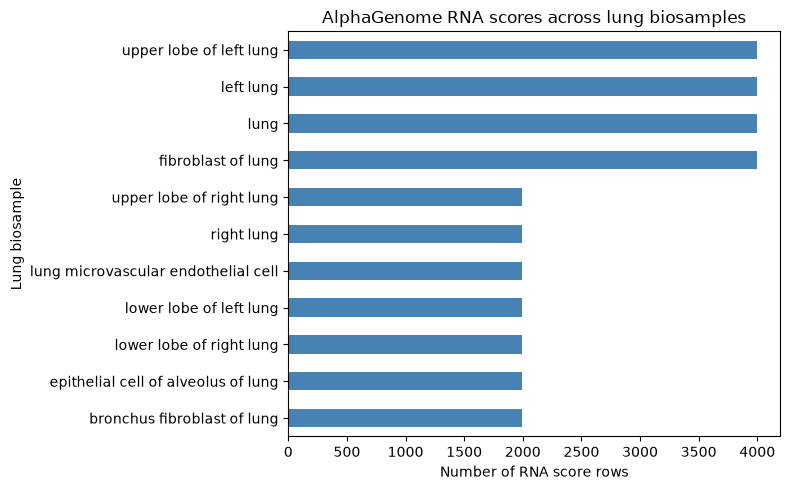

In [ ]:
# Count RNA score rows for each lung biosample
biosample_counts = (
    lung_scores.groupby("biosample_name")
    .size()
    .sort_values()
)

plt.figure(figsize=(8, 5))
biosample_counts.plot.barh(color="steelblue")

plt.xlabel("Number of RNA score rows")
plt.ylabel("Lung biosample")
plt.title("AlphaGenome RNA scores across lung biosamples")

plt.tight_layout()
plt.show()


## 10. Summarize RNA effects by gene

For each target gene, keep its largest absolute RNA effect across linked variants and lung tracks. Use exploratory cutoffs to count genes with negative, near-zero, and positive scores.

In [ ]:
# Keep the strongest predicted effect for each gene
gene_effects = lung_scores.dropna(
    subset=["target_gene", "raw_score"]
).copy()

gene_effects["abs_score"] = gene_effects["raw_score"].abs()

gene_effects = (
    gene_effects.sort_values("abs_score", ascending=False)
    .drop_duplicates("target_gene")
    .copy()
)

print(f"Genes with lung RNA predictions: {len(gene_effects):,}")

display(
    gene_effects[
        ["target_gene", "rsid", "biosample_name", "raw_score"]
    ].head(10)
)

Genes with lung RNA predictions: 179


,target_gene,rsid,biosample_name,raw_score
28944,CARMIL2,rs13334205,lung microvascular endothelial cell,-0.027391
500913,SERTAD2,rs2302643,fibroblast of lung,-0.019648
317457,PKD1,rs3087631,fibroblast of lung,0.015164
139961,ZBTB16,rs648116,lung microvascular endothelial cell,0.014892
272605,PHGR1,rs2034650,lung,0.012877
299332,ATP5F1EP1,rs17036142,left lung,0.012873
48839,TSPAN14,rs7922621,left lung,0.012575
392113,HMGN1P4,rs1129723,upper lobe of left lung,-0.011451
302845,PIMREGP2,rs111873045,lower lobe of right lung,-0.010622
613251,RPS12P4,rs3755303,upper lobe of left lung,-0.009658


In [ ]:
# Count genes at different raw score thresholds
thresholds = [0.01, 0.05, 0.10]

summary = []

for threshold in thresholds:
    scores = gene_effects["raw_score"]

    summary.append({
        "Threshold": threshold,
        "Decreased": (scores <= -threshold).sum(),
        "Near zero": (scores.abs() < threshold).sum(),
        "Increased": (scores >= threshold).sum()
    })

summary = pd.DataFrame(summary)

display(summary)

,Threshold,Decreased,Near zero,Increased
0,0.01,4,170,5
1,0.05,0,179,0
2,0.10,0,179,0


In [ ]:
# List genes with predicted RNA effects outside +/- 0.01
top_genes = gene_effects[
    gene_effects["raw_score"].abs() >= 0.01
].copy()

display(
    top_genes[
        ["target_gene", "rsid", "biosample_name", "raw_score"]
    ].sort_values("raw_score")
)

,target_gene,rsid,biosample_name,raw_score
28944,CARMIL2,rs13334205,lung microvascular endothelial cell,-0.027391
500913,SERTAD2,rs2302643,fibroblast of lung,-0.019648
392113,HMGN1P4,rs1129723,upper lobe of left lung,-0.011451
302845,PIMREGP2,rs111873045,lower lobe of right lung,-0.010622
48839,TSPAN14,rs7922621,left lung,0.012575
299332,ATP5F1EP1,rs17036142,left lung,0.012873
272605,PHGR1,rs2034650,lung,0.012877
139961,ZBTB16,rs648116,lung microvascular endothelial cell,0.014892
317457,PKD1,rs3087631,fibroblast of lung,0.015164
